<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_17_Probabilistic_Token_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part 1: PyTorch's multinomial function

## Task_1:
- Create a torch tensor of floats from the list [1,2,5]. Name the
variable vect. Run the following code multiple times to gain some
intuition for the function’s output.torch.multinomial(vect,1)
Next, run the following code several times to build some more intu
ition: vect[torch.multinomial(vect,10,replacement=True)]

In [12]:
vect=torch.tensor([1,2,5],dtype=torch.float)
torch.multinomial(vect,1)

tensor([1])

In [17]:
vect[torch.multinomial(vect,10,replacement=True)]

tensor([5., 1., 5., 5., 5., 5., 2., 5., 5., 1.])

## Task_2:
- Generate 10,000 samples from the same vector. Set the input ar
gument replacement to be true. Use torch.unique to count the
number of times each of three elements was selected. Print the count
and proportion of times that each number was selected.

In [27]:
mn=torch.multinomial(vect,10000,replacement=True)


In [23]:
type(mn)

torch.Tensor

In [26]:
mn

tensor([2, 0, 1,  ..., 2, 2, 1])

In [41]:
vect[mn]

tensor([5., 2., 5.,  ..., 5., 5., 5.])

In [28]:
vals,counts=torch.unique(mn,return_counts=True)
for v,c in zip(vals,counts):
  print(f'"{v}" was sampled {c} times ({c/len(mn):.2%})')

"0" was sampled 1250 times (12.50%)
"1" was sampled 2458 times (24.58%)
"2" was sampled 6292 times (62.92%)


## Task_3:
- Calculate the expected probability for each vector element using the
formula p(vi) = vi/ v, where vi is each element in variable vect.
Write code to print the table below.

In [29]:
print('Value | Observed | Expected')
print('------+----------+----------')

for v,c,vectval in zip(vals,counts,vect):

  observedFrequency = c/len(mn)
  expectedFrequency = vectval/torch.sum(vect)

  print(f' "{v}"  |  {observedFrequency:.2%}  |  {expectedFrequency:.2%}')

Value | Observed | Expected
------+----------+----------
 "0"  |  12.50%  |  12.50%
 "1"  |  24.58%  |  25.00%
 "2"  |  62.92%  |  62.50%


In [30]:
l=list(vect)
s=sum(l)
e=[]
for i in l:
  e.append(i/s)

print(e)

[tensor(0.1250), tensor(0.2500), tensor(0.6250)]


In [32]:
torch.multinomial??

# Part 2: Common errors with torch.multinomial

## Task_1:
- The online code file contains the following lines of code. All lines
produce errors; your goal is to understand why those errors arise and
then fix them. I will describe the problems and their solutions below.
- error 1
torch.multinomial([1.,2,.3],1)
torch.multinomial(np.array([1.,2,.3]),1)
- error 2
torch.multinomial(vect,len(vect)+1)
- error 3
torch.multinomial(torch.tensor([1,1,1]),1)
- error 4
torch.multinomial(torch.tensor([-1,1.,1]),1)

In [34]:

# # error 1: requires torch tensor
# torch.multinomial([1.,2,.3],1)
# torch.multinomial(np.array([1.,2,.3]),1)

In [36]:
len(vect)

3

In [37]:
# # error 2: default is no replacement
# torch.multinomial(vect,len(vect)+1)

In [39]:
# # error 3: only floats
# torch.multinomial(torch.tensor([1,1,1]),1)


In [40]:
# # error 4: only non-negative numbers
# torch.multinomial(torch.tensor([-1,1.,1]),1)

# Part 3: Deterministic token selection

## Task_1:
- Import the GPT-2-small model and its tokenizer. Tokenize the text
“I don’t want to grow” and input the tokens into the model. Isolate
the logits to the final token and transform to softmax.
Find the maximum logit and print its token string. Visualize
the logits as in Figure 4.9.

In [44]:
llm=AutoModelForCausalLM.from_pretrained('gpt2')
tokenizer=AutoTokenizer.from_pretrained('gpt2')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [45]:
llm.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [48]:
txt = "I don't want to grow"
tokens=tokenizer.encode(txt,return_tensors="pt")
tokens

tensor([[  40,  836,  470,  765,  284, 1663]])

In [49]:
with torch.no_grad():
  outputs=llm(tokens)
outputs

CausalLMOutputWithCrossAttentions(loss=None, logits=tensor([[[ -39.3084,  -39.0100,  -41.8374,  ...,  -46.9337,  -44.9074,
           -39.5149],
         [-261.0096, -257.7495, -262.0256,  ..., -281.6742, -287.2552,
          -263.0469],
         [-168.8854, -167.9453, -176.2264,  ..., -181.3110, -180.2301,
          -172.5459],
         [ -55.5614,  -54.1664,  -60.2187,  ...,  -60.1240,  -64.3036,
           -57.6978],
         [-145.4407, -144.6209, -152.5711,  ..., -155.5938, -157.2356,
          -148.5867],
         [-104.6927, -104.4484, -112.1426,  ..., -108.8956, -115.2077,
          -108.4659]]]), past_key_values=DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer]), hidden_states=None, attentions=None, cross_attentions=None)

In [51]:
outputs.logits.shape

torch.Size([1, 6, 50257])

In [52]:
logits=outputs.logits[0 ,-1, :].detach()

In [55]:
logits_sm=F.softmax(logits,dim=-1)

In [80]:
logits_sm.shape

torch.Size([50257])

In [60]:
logits.shape

torch.Size([50257])

In [56]:
logits.shape

torch.Size([50257])

In [57]:
max_logit=logits.argmax()

In [59]:
max_logit

tensor(510)

In [61]:
print(f'The maximum logit is #{max_logit} with a softmax probability of {logits_sm[max_logit]:.2%}')
print(f'The max word is "{tokenizer.decode(max_logit)}"')

The maximum logit is #510 with a softmax probability of 33.87%
The max word is " up"


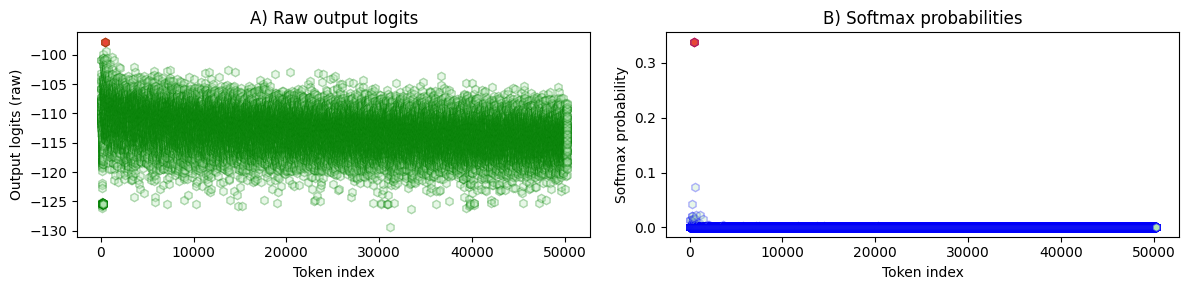

In [62]:
# plot the raw and softmax logits
_,axs = plt.subplots(1,2,figsize=(12,3))

axs[0].plot(max_logit,logits[max_logit],'rh')
axs[0].plot(logits,'gh',linewidth=.2,markerfacecolor=[.7,.9,.7,.3])
axs[0].set(xlabel='Token index',ylabel='Output logits (raw)',title='A) Raw output logits')

axs[1].plot(max_logit,logits_sm[max_logit],'rh')
axs[1].plot(logits_sm,'bh',linewidth=.2,markerfacecolor=[.7,.9,.7,.3])
axs[1].set(xlabel='Token index',ylabel='Softmax probability',title='B) Softmax probabilities')

plt.tight_layout()
plt.show()

# Part 4: Multinomial probabilistic selection

## Task_1:
- Use the multinomial function to select 10 tokens at random, from
the entire vocab, with replacement. Print the 10 sentences along with
the new-token probabilities. Run the code multiple times to observe
the differences.

In [67]:
for t in torch.multinomial(logits_sm,10,replacement=True):
  print(f'{txt}"{tokenizer.decode(t)}"\t({logits_sm[t]:.2%})')

I don't want to grow" more"	(0.44%)
I don't want to grow" in"	(2.07%)
I don't want to grow" in"	(2.07%)
I don't want to grow" up"	(33.87%)
I don't want to grow" my"	(7.40%)
I don't want to grow" up"	(33.87%)
I don't want to grow" longer"	(0.03%)
I don't want to grow" genetically"	(0.00%)
I don't want to grow" up"	(33.87%)
I don't want to grow" up"	(33.87%)


# Part 5: Top-k sampling

## Task_1:
- Find the tokens with the 10 largest logits. Print the token indices,
softmax-probabilities, and token strings, as you see below.
Calculate the total probability mass explained by the top 10
tokens.
Will you get different results each time you run the code? Think of
your answer before confirming it.

In [69]:
k=10
top_k=torch.topk(logits_sm,k)
print(txt,'___\n')
for i in range(k):
  val=top_k.values[i]
  tok=top_k.indices[i]
  print(f'{tok:5} ({val:5.1%}) is "{tokenizer.decode(tok)}"')

I don't want to grow ___

  510 (33.9%) is " up"
  616 ( 7.4%) is " my"
  257 ( 4.4%) is " a"
 1165 ( 2.3%) is " too"
  656 ( 2.2%) is " into"
  262 ( 2.1%) is " the"
  287 ( 2.1%) is " in"
  428 ( 1.7%) is " this"
  340 ( 1.6%) is " it"
 1468 ( 1.5%) is " old"


In [76]:
top_k

torch.return_types.topk(
values=tensor([0.3387, 0.0740, 0.0436, 0.0230, 0.0218, 0.0208, 0.0207, 0.0172, 0.0158,
        0.0151]),
indices=tensor([ 510,  616,  257, 1165,  656,  262,  287,  428,  340, 1468]))

In [70]:

print(f'The top {k} options account for {logits_sm[top_k.indices].sum():.1%} of the probability mass.')


The top 10 options account for 59.1% of the probability mass.


## Task_2:
- Renormalize the top-10 raw logits back into softmax probabilities to
form a new probability distribution of only the top-10 values.
Use the multinomial function to generate 10 new sentences
by sampling from the top-10 distribution

In [77]:
# re-normalize to sum to 1
sm_top_k = F.softmax(logits[top_k.indices],dim=-1)

In [78]:
sm_top_k

tensor([0.5735, 0.1252, 0.0739, 0.0389, 0.0370, 0.0352, 0.0350, 0.0291, 0.0267,
        0.0255])

In [82]:
print(sm_top_k.sum())

tensor(1.0000)


In [85]:
top_k.indices

tensor([ 510,  616,  257, 1165,  656,  262,  287,  428,  340, 1468])

In [92]:
for t in torch.multinomial(sm_top_k,10):
  tidx = top_k.indices[t] # token index into vocab (not top-k)
  print(f'{txt}"{tokenizer.decode(tidx)}"\t({sm_top_k[t]:6.2%})')

I don't want to grow" up"	(57.35%)
I don't want to grow" it"	( 2.67%)
I don't want to grow" my"	(12.52%)
I don't want to grow" too"	( 3.89%)
I don't want to grow" a"	( 7.39%)
I don't want to grow" into"	( 3.70%)
I don't want to grow" in"	( 3.50%)
I don't want to grow" the"	( 3.52%)
I don't want to grow" old"	( 2.55%)
I don't want to grow" this"	( 2.91%)
